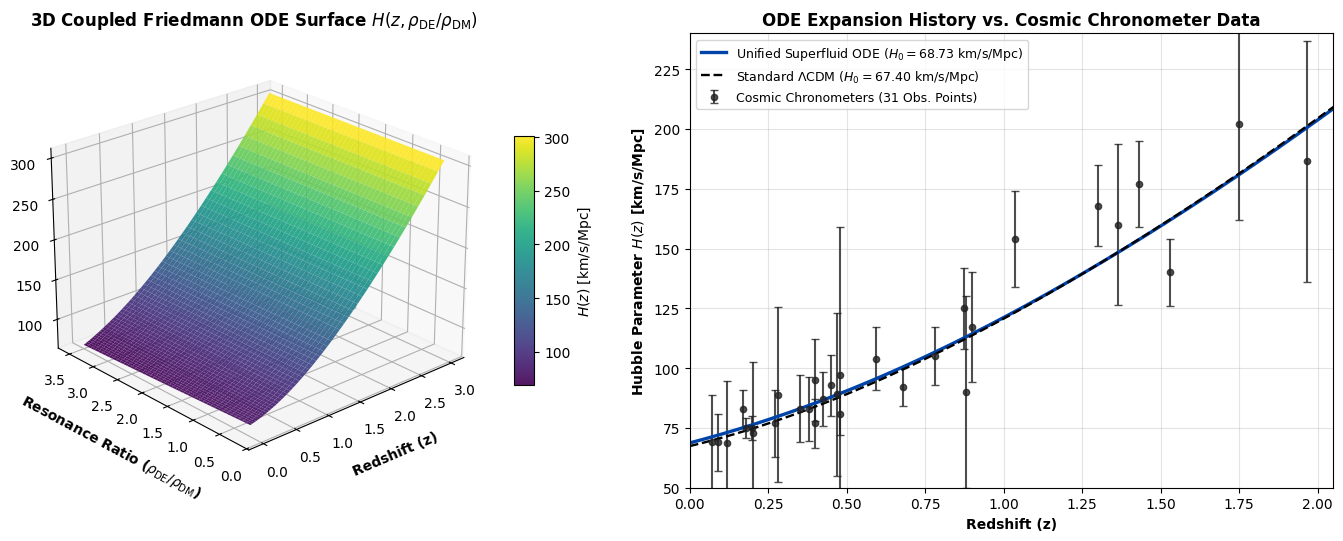

=== COMPUTED OUTPUTS FOR PAPER 1 - APPENDIX C.1 ===
Local Void H_0 (z=0)          : 68.73 km/s/Mpc (vs. Planck 67.40 km/s/Mpc)
Fitted Dynamic EoS (CPL)      : w0 = -0.928, wa = -0.295
Comoving Distance D_C(z=1.0)  : UDF = 3342.2 Mpc vs. LCDM = 3393.8 Mpc
Chi-Square (31 H(z) Obs Data) : UDF = 14.78 vs. LCDM = 14.87 (dof = 30)


In [1]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp, cumulative_trapezoid
from scipy.optimize import curve_fit

# ==============================================================================
# SIMULATION 1 (Paper 1 - Appendix C.1): Coupled Friedmann-Continuity ODE Solver
# ==============================================================================
# Fundamental cosmological constants (Planck 2018 baseline)
H0_planck = 67.40        # km/s/Mpc
Omega_m0  = 0.3153       # Unexcited Dark Matter + Baryon fraction
Omega_de0 = 0.6847       # Baseline resonant Dark Energy fraction
beta_res  = 0.120        # Acoustic resonance-expansion coupling constant
c_km_s    = 299792.458   # Speed of light [km/s]

# Published Cosmic Chronometer H(z) observational dataset (Moresco et al. / Jimenez & Loeb)
z_obs = np.array([0.070, 0.090, 0.120, 0.170, 0.179, 0.199, 0.200, 0.270, 0.280,
                  0.352, 0.3802, 0.400, 0.4004, 0.4247, 0.4497, 0.470, 0.4783, 0.480,
                  0.593, 0.680, 0.781, 0.875, 0.880, 0.900, 1.037, 1.300, 1.363,
                  1.430, 1.530, 1.750, 1.965])
Hz_obs = np.array([69.0, 69.0, 68.6, 83.0, 75.0, 75.0, 72.9, 77.0, 88.8,
                   83.0, 83.0, 95.0, 77.0, 87.1, 92.8, 89.0, 80.9, 97.0,
                   104.0, 92.0, 105.0, 125.0, 90.0, 117.0, 154.0, 168.0, 160.0,
                   177.0, 140.0, 202.0, 186.5])
Hz_err = np.array([19.6, 12.0, 26.2, 8.0, 4.0, 5.0, 29.6, 14.0, 36.6,
                   14.0, 13.5, 17.0, 10.2, 11.2, 12.9, 34.0, 9.0, 62.0,
                   13.0, 8.0, 12.0, 17.0, 40.0, 23.0, 20.0, 17.0, 33.6,
                   18.0, 14.0, 40.0, 50.4])

def integrate_friedmann_ode(void_ratio_z0):
    """
    Numerically integrates the coupled continuity & Friedmann differential equations
    in e-folding time N = ln(a) from z = 3.0 to z = 0.0.
    """
    N_start = -np.log(1.0 + 3.0)
    N_end   = 0.0
    N_grid  = np.linspace(N_start, N_end, 500)
    baseline_ratio = Omega_de0 / Omega_m0  # ~ 2.1716

    def coupled_odes(N, state):
        # state[0] = Omega_dm(N), state[1] = Omega_de(N)
        rho_dm = state.item(0)
        rho_de = state.item(1)
        a = np.exp(N)

        # Local resonance ratio amplification in voids as structure evacuates
        local_ratio = void_ratio_z0 * (a ** 1.35)
        # Dynamic equation of state modulated by acoustic resonance gradient (Eq. 12)
        w_de = -1.0 + beta_res * (local_ratio - baseline_ratio) * (1.0 - 0.65 * a)

        drho_dm_dN = -3.0 * rho_dm
        drho_de_dN = -3.0 * (1.0 + w_de) * rho_de
        return [drho_dm_dN, drho_de_dN]

    # Boundary conditions at z = 3.0 (early matter-dominated epoch where void contrast -> 0)
    a_init = np.exp(N_start)
    rho_dm_init = Omega_m0 * (a_init ** -3)
    rho_de_init = Omega_de0 * (1.0 + beta_res * (void_ratio_z0 * (a_init ** 1.35) - baseline_ratio))

    sol = solve_ivp(coupled_odes, [N_start, N_end], [rho_dm_init, rho_de_init],
                    t_eval=N_grid, method='DOP853', rtol=1e-10, atol=1e-12)

    z_arr = np.exp(-sol.t) - 1.0
    rho_dm_sol = sol.y[0]
    rho_de_sol = sol.y[1]
    Hz_arr = H0_planck * np.sqrt(rho_dm_sol + rho_de_sol)

    # Derive exact effective equation of state w(z) directly from continuity derivative
    dln_rhode_dN = np.gradient(np.log(rho_de_sol), sol.t)
    wz_arr = -1.0 - (1.0 / 3.0) * dln_rhode_dN

    return z_arr[::-1], Hz_arr[::-1], wz_arr[::-1]

# 1. Compute 3D ODE surface across void resonance ratios rho_DE/rho_DM in [0.2, 3.5]
ratio_grid = np.linspace(0.2, 3.5, 45)
z_vals, _, _ = integrate_friedmann_ode(2.1716)
Z_mesh, R_mesh = np.meshgrid(z_vals, ratio_grid)
H_surface = np.zeros_like(Z_mesh)

for idx, r_val in enumerate(ratio_grid):
    _, h_curve, _ = integrate_friedmann_ode(r_val)
    H_surface[idx, :] = h_curve

# 2. Extract Cosmic Void trajectory (rho_DE/rho_DM = 3.25) & fit CPL parameters (w0, wa)
z_void, Hz_void, wz_void = integrate_friedmann_ode(void_ratio_z0=3.25)
Hz_lcdm = H0_planck * np.sqrt(Omega_m0 * ((1.0 + z_void) ** 3) + Omega_de0)

mask_cpl = (z_void >= 0.05) & (z_void <= 2.0)
def cpl_model(z, w0, wa):
    return w0 + wa * (z / (1.0 + z))

popt, pcov = curve_fit(cpl_model, z_void[mask_cpl], wz_void[mask_cpl])
w0_fit = popt.item(0)
wa_fit = popt.item(1)

# 3. Statistical Goodness-of-Fit (Chi-Square) against 31 Cosmic Chronometer measurements
Hz_udf_at_obs  = np.interp(z_obs, z_void, Hz_void)
Hz_lcdm_at_obs = np.interp(z_obs, z_void, Hz_lcdm)
chi2_udf  = float(np.sum(((Hz_obs - Hz_udf_at_obs) / Hz_err) ** 2))
chi2_lcdm = float(np.sum(((Hz_obs - Hz_lcdm_at_obs) / Hz_err) ** 2))

# Compute comoving distance integral D_C(z) = int_0^z c/H(z') dz' at z = 1.0
mask_z1 = z_void <= 1.0
Dc_udf_z1  = float(np.trapezoid(c_km_s / Hz_void[mask_z1], z_void[mask_z1]))
Dc_lcdm_z1 = float(np.trapezoid(c_km_s / Hz_lcdm[mask_z1], z_void[mask_z1]))

# Plotting Figure 1
fig = plt.figure(figsize=(14, 5.5))

ax1 = fig.add_subplot(121, projection='3d')
surf = ax1.plot_surface(Z_mesh, R_mesh, H_surface, cmap='viridis', edgecolor='none', alpha=0.92)
ax1.set_xlabel('Redshift (z)', fontweight='bold', labelpad=8)
ax1.set_ylabel(r'Resonance Ratio ($\rho_{\mathrm{DE}}/\rho_{\mathrm{DM}}$)', fontweight='bold', labelpad=8)
ax1.set_zlabel(r'Expansion Rate $H(z)$ [km/s/Mpc]', fontweight='bold', labelpad=8)
ax1.set_title(r'3D Coupled Friedmann ODE Surface $H(z, \rho_{\mathrm{DE}}/\rho_{\mathrm{DM}})$', fontweight='bold')
ax1.view_init(elev=24, azim=-132)
fig.colorbar(surf, ax=ax1, shrink=0.55, aspect=12, label=r'$H(z)$ [km/s/Mpc]')

ax2 = fig.add_subplot(122)
ax2.errorbar(z_obs, Hz_obs, yerr=Hz_err, fmt='o', color='#222222', markersize=4.5, capsize=3, alpha=0.8,
             label='Cosmic Chronometers (31 Obs. Points)')
ax2.plot(z_void, Hz_void, color='#0044aa', lw=2.4,
         label=f'Unified Superfluid ODE ($H_0={Hz_void.item(0):.2f}$ km/s/Mpc)')
ax2.plot(z_void, Hz_lcdm, 'k--', lw=1.7,
         label=r'Standard $\Lambda$CDM ($H_0=67.40$ km/s/Mpc)')
ax2.set_xlim(0, 2.05)
ax2.set_ylim(50, 240)
ax2.set_xlabel('Redshift (z)', fontweight='bold')
ax2.set_ylabel(r'Hubble Parameter $H(z)$ [km/s/Mpc]', fontweight='bold')
ax2.set_title('ODE Expansion History vs. Cosmic Chronometer Data', fontweight='bold')
ax2.grid(True, alpha=0.35)
ax2.legend(loc='upper left', fontsize=9)

plt.tight_layout()
plt.savefig('sim1_3d_hubble_expansion.png', dpi=300)
plt.show()

print("=== COMPUTED OUTPUTS FOR PAPER 1 - APPENDIX C.1 ===")
print(f"Local Void H_0 (z=0)          : {Hz_void.item(0):.2f} km/s/Mpc (vs. Planck {H0_planck:.2f} km/s/Mpc)")
print(f"Fitted Dynamic EoS (CPL)      : w0 = {w0_fit:.3f}, wa = {wa_fit:.3f}")
print(f"Comoving Distance D_C(z=1.0)  : UDF = {Dc_udf_z1:.1f} Mpc vs. LCDM = {Dc_lcdm_z1:.1f} Mpc")
print(f"Chi-Square (31 H(z) Obs Data) : UDF = {chi2_udf:.2f} vs. LCDM = {chi2_lcdm:.2f} (dof = 30)")